<a href="https://colab.research.google.com/github/ikwak2/bio_sig_class/blob/main/02_ecg_feature_ml_teaching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 2. ECG 특징을 머신러닝 분류에 연결하기

**데이터와 정답 이해 → 46개 특징 → 전처리·ML 학습 → 검증에서 선택 → 시험 평가 → 해석**

목표는 **30초 ECG 안에 전문가가 `V`로 주석한 박동이 하나 이상 있는지** 예측하는 것입니다. `V`는 심실조기수축(PVC) 주석입니다.

- **입력 X:** 파형과 자동 검출 박동으로 계산한 46개 특징입니다.
- **정답 y:** 30초 안에 전문가 `V` 주석이 있으면 1, 없으면 0입니다.
- **음성의 의미:** V가 없다는 뜻이며 정상 환자나 정상 동율동을 뜻하지 않습니다. 다른 주석 `E`, `F` 등은 이번 양성 정의에 포함하지 않습니다.

실습 1의 특징 함수를 포함한 독립 실행 자료입니다. 위에서부터 순서대로 실행하면 됩니다. 기본 설정은 **MIT-BIH 12개 기록의 전체 길이**이며, **한 행은 박동 하나가 아니라 30초 창 하나**입니다.

배울 내용은 세 가지입니다: ① 정답 정보 없이 특징 만들기, ② 훈련 자료 안에서 전처리와 모델 학습하기, ③ 검증에서 모델·임계값을 고정하고 시험에서 평가하기.

## 1. 데이터셋과 분할

현재 코드의 기록 목록은 다음과 같습니다. 기본 전체 길이에서는 각 기록이 119개 창으로 나뉩니다.

| 분할 | 기록 번호 | 기록 수 / 창 수 | 역할 |
|---|---|---|---|
| train | 100, 101, 103, 106, 108, 119 | 6 / 714 | 결측 대체·표준화·모델 학습 |
| validation | 105, 112, 200 | 3 / 357 | 모델과 임계값 선택 |
| test | 117, 203, 208 | 3 / 357 | 고정한 선택의 최종 평가 |
| 합계 | 12개 기록 | 12 / 1,428 | 한 행은 30초 창 |

**30초 창, 15초 hop**이므로 이웃 창은 절반이 겹칩니다. 같은 기록의 창 전체를 같은 분할에 두어, 비슷한 파형이 train과 test에 함께 들어가는 것을 막습니다. 여러 기록이 같은 환자에게서 나온 데이터로 확장한다면 환자 단위로 묶어야 합니다.

`MAX_SECONDS=None`은 전체 길이입니다. `600`이면 각 기록의 첫 10분만 사용하므로 행 수·라벨 분포·성능이 달라집니다. 위 숫자는 기본 설정 기준이며 실제 출력으로 확인합니다.

In [1]:
%pip install -q wfdb


In [2]:
from pathlib import Path
import json, hashlib, urllib.request, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.integrate import trapezoid
import pywt, wfdb, joblib
from wfdb import processing
from IPython.display import display

# Pipeline은 결측 대체·표준화·분류기를 하나로 묶어 같은 순서로 fit/예측하게 합니다.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
    balanced_accuracy_score, precision_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'mitdb'
RESULTS = ROOT / 'results' / 'ml_practice'
RESULTS.mkdir(parents=True, exist_ok=True)
# 실제로 사용하는 기록은 12개입니다. 행을 섞어 분할하지 않고 기록별로 역할을 고정합니다.
SPLITS = {
    'train': ['100', '101', '103', '106', '108', '119'],
    'val': ['105', '112', '200'],
    'test': ['117', '203', '208'],
}
# ML 특징은 원본 360 Hz에서 계산합니다. 30초는 한 채널 10,800개 샘플입니다.
FS = 360
SEED = 42
# 데이터 길이를 바꾸면 창 수·라벨 분포도 바뀝니다. 모델 평가 전에 정합니다.
MAX_SECONDS = None  # None=전체 기록; 빠른 실행은 600. 실행 전 고정합니다.
WINDOW_S, HOP_S = 30, 15
POSITIVE_SYMBOL = 'V'
CLASS_NAMES = ['No V', 'V present']
assert len(set(sum(SPLITS.values(), []))) == sum(map(len, SPLITS.values()))
print('분할:', SPLITS)
print('라벨: 30초 안에 V가 1개 이상이면 1')


분할: {'train': ['100', '101', '103', '106', '108', '119'], 'val': ['105', '112', '200'], 'test': ['117', '203', '208']}
라벨: 30초 안에 V가 1개 이상이면 1


In [3]:
def download_record(record):
    if record not in sum(SPLITS.values(), []):
        raise ValueError('Record not included in the teaching manifest')
    DATA.mkdir(parents=True, exist_ok=True)
    # hea=신호 설명, dat=파형, atr=전문가 주석. 받은 파일은 재사용합니다.
    for ext in ['hea','dat','atr']:
        dest = DATA / f'{record}.{ext}'
        if not dest.exists():
            url = f'https://physionet.org/files/mitdb/1.0.0/{dest.name}'
            tmp = dest.with_suffix(dest.suffix+'.part')
            try:
                with urllib.request.urlopen(url, timeout=90) as src:
                    tmp.write_bytes(src.read())
                tmp.replace(dest)
            finally:
                tmp.unlink(missing_ok=True)
    return DATA / record

def read_record(record):
    p=download_record(record)
    rec=wfdb.rdrecord(str(p))
    ann=wfdb.rdann(str(p),'atr')
    assert rec.fs == FS
    # MLII를 우선 선택하고 이름이 없으면 첫 채널을 사용합니다.
    lead = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    return rec,ann,lead


## 2. 먼저 파형과 V 주석 확인하기

기록 106의 `V` 하나를 선택해 앞뒤 3초를 그립니다. 초록 점은 `N` 주석, 빨간 점·점선은 `V` 주석입니다. 그림은 추가 필터를 적용하지 않은 원본 물리 단위 파형입니다.

`RECORD`는 기록 번호, `V_INDEX`는 그 기록의 몇 번째 V를 볼지 정하는 값입니다. **이 그림은 주석의 의미를 이해하기 위한 예시**이며, 아래 특징 계산에는 전문가의 박동 위치·종류를 넣지 않습니다.

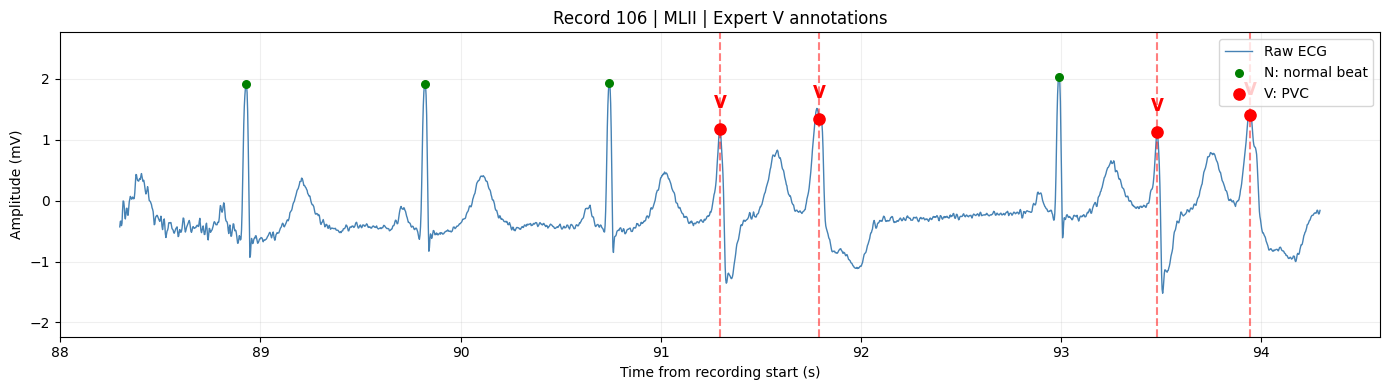

기록 전체의 V 주석 수: 520개
선택한 V 위치: 91.297초


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# 이 셀은 라벨 이해용 그림입니다. 전문가 위치를 아래 입력 특징으로 넘기지 않습니다.
RECORD = '106'       # 확인할 기록
V_INDEX = 0          # 0: 첫 번째 V, 1: 두 번째 V, ...
BEFORE_S = 3        # 선택한 V 이전 몇 초?
AFTER_S = 3         # 선택한 V 이후 몇 초?

# 1. 원본 ECG와 전문가 주석 읽기
rec, ann, lead = read_record(RECORD)
fs = float(rec.fs)

# p_signal: 물리 단위로 변환된 원본 신호. 추가 필터링하지 않습니다.
raw = rec.p_signal[:, lead]
unit = rec.units[lead]

ann_samples = np.asarray(ann.sample)
ann_symbols = np.asarray(ann.symbol)

# 2. 전문가 주석 중 V 위치만 선택
v_samples = ann_samples[ann_symbols == 'V']

if len(v_samples) == 0:
    print(f'기록 {RECORD}에는 V 주석이 없습니다.')

elif not 0 <= V_INDEX < len(v_samples):
    print(f'V_INDEX는 0부터 {len(v_samples)-1}까지 가능합니다.')

else:
    # 3. 선택한 V를 중심으로 표시 범위 설정
    selected_v = int(v_samples[V_INDEX])
    start = max(0, selected_v - int(BEFORE_S * fs))
    end = min(len(raw), selected_v + int(AFTER_S * fs))

    # 샘플 인덱스를 초로 바꿉니다. y축은 rec.units에 기록된 물리 단위입니다.
    time = np.arange(start, end) / fs

    # 표시 범위 안에 있는 V와 N 주석
    visible_v = v_samples[
        (v_samples >= start) & (v_samples < end)
    ]

    visible_n = ann_samples[
        (ann_symbols == 'N') &
        (ann_samples >= start) &
        (ann_samples < end)
    ]

    # 4. 원본 파형 그리기
    fig, ax = plt.subplots(figsize=(14, 4))

    ax.plot(
        time, raw[start:end],
        color='steelblue', lw=1,
        label='Raw ECG'
    )

    # N 주석: 초록 점
    ax.scatter(
        visible_n / fs, raw[visible_n],
        color='green', s=30, zorder=3,
        label='N: normal beat'
    )

    # V 주석: 빨간 점과 수직선
    ax.scatter(
        visible_v / fs, raw[visible_v],
        color='red', s=65, zorder=4,
        label='V: PVC'
    )

    for sample in visible_v:
        ax.axvline(
            sample / fs,
            color='red', ls='--', alpha=0.5
        )
        ax.annotate(
            'V',
            xy=(sample / fs, raw[sample]),
            xytext=(0, 15),
            textcoords='offset points',
            ha='center', color='red',
            fontsize=12, fontweight='bold'
        )

    ax.set(
        xlabel='Time from recording start (s)',
        ylabel=f'Amplitude ({unit})',
        title=f'Record {RECORD} | {rec.sig_name[lead]} | Expert V annotations'
    )
    ax.grid(alpha=0.2)
    ax.legend(loc='upper right')
    ax.margins(y=0.2)

    plt.tight_layout()
    plt.show()

    print(f'기록 전체의 V 주석 수: {len(v_samples)}개')
    print(f'선택한 V 위치: {selected_v / fs:.3f}초')


## 3. 신호를 46개 특징으로 요약하기

한 채널을 **360 Hz 그대로** 사용합니다. 30초는 `360×30=10,800`개 진폭 값입니다. 기록 전체에 0.5–40 Hz 양방향 필터를 적용한 뒤 창을 나누고, 창마다 다음 특징을 계산합니다.

| 특징군 | 개수 | 요약하는 정보 |
|---|---:|---|
| 시간영역 | 12 | 평균·분산·RMS, 분포 모양, 파형 변화 정도 |
| Welch 주파수 | 11 | 대역별 파워와 주파수 분포 |
| STFT | 6 | 대역 비중의 시간 평균·표준편차 |
| 웨이블릿 | 6 | 여러 시간 척도 성분의 상대 에너지 |
| RR | 8 | 자동 검출 박동 수, 간격의 평균·변동 |
| 박동 모양 | 3 | 완전한 박동 수, 대표 모양과의 상관 |
| 합계 | **46** | 30초 파형을 46개 숫자로 표현 |

박동 위치는 **XQRS 자동 검출**을 사용합니다. RR은 검출된 모든 간격이며, 정상 박동만 정제한 임상 NN-HRV와 구분합니다. 양방향 필터와 기록 전체 검출을 사용하는 오프라인 실습입니다.

아래 함수는 실습 1의 계산법입니다. ML 흐름을 먼저 공부한다면 이 표를 확인한 뒤 **4번의 특징표 생성**으로 넘어가도 됩니다. 원파형을 구간별 z-score로 바꾸지는 않으므로 진폭 특징에는 mV 단위가 남습니다.

In [7]:
# 기록 전체를 0.5~40 Hz 양방향 필터링합니다.
def filtered(x):
    sos = signal.butter(
        4,
        [0.5, 40],
        btype='bandpass',
        fs=FS,
        output='sos'
    )
    return signal.sosfiltfilt(sos, x)


In [8]:
def validate_segment(segment, fs):
    z = np.asarray(segment, dtype=float)
    if z.ndim != 1 or not np.isfinite(z).all():
        raise ValueError('유한한 값만 포함한 1차원 신호가 필요합니다.')
    if not np.isfinite(fs) or fs <= 0 or len(z) < max(4, int(2 * fs)):
        raise ValueError('양의 fs와 최소 2초 신호가 필요합니다.')
    return z

def time_features(segment, fs):
    z = validate_segment(segment, fs)
    v = float(np.var(z))
    # 시간 미분을 근사합니다. fs를 곱해 샘플 간 차이를 초당 변화량으로 바꿉니다.
    dz = np.diff(z) * fs
    ddz = np.diff(dz) * fs
    vd, vdd = float(np.var(dz)), float(np.var(ddz))
    # Hjorth activity는 분산, mobility는 변화 속도, complexity는 변화 속도의 복잡도를
    # 요약합니다.
    mobility = np.sqrt(vd / v) if v > 1e-24 else np.nan
    complexity = (np.sqrt(vdd / vd) / mobility
                  if vd > 1e-24 and np.isfinite(mobility) and mobility > 0
                  else np.nan)
    # fs개 샘플은 1초입니다. 1초 떨어진 파형의 상관을 계산합니다.
    lag = int(round(fs))
    a, b = z[:-lag], z[lag:]
    ac = (float(np.corrcoef(a, b)[0, 1])
          if np.std(a) > 1e-12 and np.std(b) > 1e-12 else np.nan)
    return {
        'mean_mV': float(np.mean(z)),
        'std_mV': float(np.std(z)),
        'rms_mV': float(np.sqrt(np.mean(z**2))),
        'iqr_mV': float(np.percentile(z, 75) - np.percentile(z, 25)),
        'peak_to_peak_mV': float(np.ptp(z)),
        'skewness': float(stats.skew(z, bias=False)) if v > 1e-24 else np.nan,
        'excess_kurtosis': float(stats.kurtosis(z, fisher=True, bias=False)) if v > 1e-24 else np.nan,
        'mean_abs_diff_mV': float(np.mean(np.abs(np.diff(z)))),
        'hjorth_activity_mV2': v,
        'hjorth_mobility_per_s': float(mobility),
        'hjorth_complexity': float(complexity),
        'autocorr_1s': ac,
    }


In [9]:
ECG_BANDS = {'0p5_5': (0.5, 5.0), '5_15': (5.0, 15.0), '15_40': (15.0, 40.0)}

def psd_estimate(segment, fs):
    z = validate_segment(segment, fs)
    if fs <= 80:
        raise ValueError('0.5–40 Hz 특징에는 fs > 80 Hz가 필요합니다.')
    # Welch는 2초 Hann 창을 겹쳐 평균합니다. PSD 적분의 단위는 mV²입니다.
    nperseg = min(len(z), int(round(2 * fs)))
    return signal.welch(z, fs=fs, window='hann', nperseg=nperseg,
                        noverlap=nperseg//2, detrend='constant', scaling='density')

def band_integral(freq, power, low, high):
    # 양 끝 경계를 보간해 인접 대역을 적분할 때 빈 경계 누락을 줄입니다.
    inside = (freq > low) & (freq < high)
    ff = np.r_[low, freq[inside], high]
    pp = np.interp(ff, freq, power)
    return float(trapezoid(pp, ff))

def spectral_features(segment, fs):
    freq, power = psd_estimate(segment, fs)
    # 0.5~40 Hz 파워로 나누면 같은 구간 안의 상대 대역 파워를 얻습니다.
    total = band_integral(freq, power, 0.5, 40)
    out = {'power_total_0p5_40_mV2': total}
    for name, (lo, hi) in ECG_BANDS.items():
        value = band_integral(freq, power, lo, hi)
        out[f'power_{name}_mV2'] = value
        out[f'rel_power_{name}'] = value / total if total > 1e-24 else np.nan
    keep = (freq >= 0.5) & (freq <= 40)
    ff, pp = freq[keep], power[keep]
    if total > 1e-24 and pp.sum() > 0:
        # 선택 주파수의 PSD를 합이 1인 비중으로 바꿔 중심·누적 경계·엔트로피를 요약합니다.
        probs = pp / pp.sum()
        positive = probs > 0
        out.update({
            'spectral_peak_hz': float(ff[np.argmax(pp)]),
            'spectral_centroid_hz': float(np.sum(ff * probs)),
            # 균일한 빈의 누적 PSD 합으로 근사합니다.
            'spectral_edge95_hz': float(ff[np.searchsorted(np.cumsum(probs), .95)]),
            'spectral_entropy_norm': float(-np.sum(probs[positive]*np.log(probs[positive])) / np.log(len(probs))),
        })
    else:
        out.update(dict.fromkeys(['spectral_peak_hz', 'spectral_centroid_hz',
                                  'spectral_edge95_hz', 'spectral_entropy_norm'], np.nan))
    return out


In [10]:
def stft_features(segment, fs):
    z = validate_segment(segment, fs)
    # 1초 창, 0.25초 이동입니다. 각 프레임의 대역 비중을 구해 시간 평균/표준편차로 요약합니다.
    n = int(round(fs))
    freq, times, zz = signal.stft(z, fs=fs, window='hann', nperseg=n,
                                 noverlap=n-int(round(.25*fs)),
                                 boundary=None, padded=False)
    power = np.abs(zz)**2
    # 프레임마다 0.5~40 Hz 성분의 합을 구합니다. 앞 Welch의 절대 대역 파워와는 구분합니다.
    total = power[(freq >= .5) & (freq <= 40)].sum(axis=0)
    out = {}
    for name, (lo, hi) in ECG_BANDS.items():
        # 이산 빈이 두 대역에 중복 배정되지 않도록 마지막 대역만 상단 포함
        mask = (freq >= lo) & ((freq <= hi) if hi == 40 else (freq < hi))
        relative = np.divide(power[mask].sum(axis=0), total,
                             out=np.full(total.shape, np.nan), where=total > 1e-24)
        valid = relative[np.isfinite(relative)]
        out[f'stft_rel_{name}_mean'] = float(valid.mean()) if len(valid) else np.nan
        out[f'stft_rel_{name}_std'] = float(valid.std()) if len(valid) else np.nan
    return out


In [11]:
def wavelet_features(segment, fs):
    z = validate_segment(segment, fs)
    wavelet = pywt.Wavelet('db4')
    if pywt.dwt_max_level(len(z), wavelet.dec_len) < 5:
        raise ValueError('db4 5단계 분해에 충분한 길이가 필요합니다.')
    # db4의 5단계 분해로 느린 성분 A5와 세부 성분 D5~D1을 얻습니다.
    coeffs = pywt.wavedec(z, wavelet, mode='periodization', level=5)
    names = ['A5', 'D5', 'D4', 'D3', 'D2', 'D1']
    energy = np.array([np.sum(c*c) for c in coeffs], dtype=float)
    # 각 성분의 제곱합을 전체 제곱합으로 나눈 상대 에너지 6개를 반환합니다.
    relative = energy/energy.sum() if energy.sum() > 1e-24 else np.full(6, np.nan)
    return {f'wavelet_db4_{name}_rel_energy': float(value)
            for name, value in zip(names, relative)}


In [12]:
def rr_features(peaks, fs):
    peaks = np.asarray(peaks, dtype=float)
    if peaks.ndim != 1 or not np.isfinite(peaks).all() or (np.diff(peaks) <= 0).any():
        raise ValueError('박동 인덱스는 1차원이며 유한하고 오름차순이어야 합니다.')
    # 자동 검출 위치 사이의 간격을 초로 바꿉니다. 전문가 N/V 종류는 입력받지 않습니다.
    rr = np.diff(peaks) / fs
    out = {'n_rpeaks': int(len(peaks)), 'n_rr': int(len(rr))}
    keys = ['rr_mean_s', 'sd_rr_ms', 'rr_cv', 'rmssd_rr_ms', 'pnn50_rr_pct', 'mean_hr_from_rr_bpm']
    # 간격이 너무 적으면 변동 특징을 NaN으로 남깁니다. 0으로 임의 해석하지 않습니다.
    if len(rr) < 3:
        out.update(dict.fromkeys(keys, np.nan))
        return out
    # 이웃 RR 간격의 차이입니다. RMSSD는 이 차이의 제곱 평균에 제곱근을 취합니다.
    dr = np.diff(rr)
    out.update({
        'rr_mean_s': float(rr.mean()),
        'sd_rr_ms': float(1000*np.std(rr, ddof=1)),
        'rr_cv': float(np.std(rr, ddof=1)/rr.mean()),
        'rmssd_rr_ms': float(1000*np.sqrt(np.mean(dr**2))),
        'pnn50_rr_pct': float(100*np.mean(np.abs(dr) > .050)),
        'mean_hr_from_rr_bpm': float(60/rr.mean()),
    })
    return out


In [13]:
def aligned_beats(segment, peaks, fs):
    z = np.asarray(segment, dtype=float)
    # 각 검출 박동의 앞 0.2초와 뒤 0.4초가 온전히 있는 경우만 파형을 정렬합니다.
    left, right = int(round(.2*fs)), int(round(.4*fs))
    valid = [int(p) for p in peaks if p >= left and p+right <= len(z)]
    return (np.stack([z[p-left:p+right] for p in valid]) if valid
            else np.empty((0, left+right)))

def morphology_features(segment, peaks, fs):
    beats = aligned_beats(segment, peaks, fs)
    out = {'n_complete_beats': int(len(beats))}
    if len(beats) < 3:
        out.update({'beat_template_corr_mean': np.nan, 'beat_template_corr_std': np.nan})
        return out
    # 그 창 안의 박동들로 중앙값 템플릿을 만들고 모양의 일관성을 상관으로 요약합니다.
    template = np.median(beats, axis=0)
    correlations = np.array([np.corrcoef(b, template)[0, 1]
                             for b in beats if np.std(b) > 1e-12 and np.std(template) > 1e-12])
    out.update({'beat_template_corr_mean': float(correlations.mean()) if len(correlations) else np.nan,
                'beat_template_corr_std': float(correlations.std()) if len(correlations) else np.nan})
    return out


In [14]:
def feature_table(ecg, peaks, fs, record_id, split_name, window_s=30, hop_s=15):
    z = validate_segment(ecg, fs)
    if window_s < 2 or hop_s <= 0:
        raise ValueError('window_s >= 2, hop_s > 0 조건이 필요합니다.')
    # 30초 창 폭은 10,800샘플, 15초 이동 폭은 5,400샘플입니다.
    width, hop = int(round(window_s*fs)), int(round(hop_s*fs))
    if hop < 1:
        raise ValueError('hop이 1표본 이상이어야 합니다.')
    rows = []
    for start in range(0, len(z)-width+1, hop):
        end = start+width
        segment = z[start:end]
        # 이 창에 들어온 자동 검출 위치를 창 시작=0의 상대 인덱스로 바꿉니다.
        local_peaks = peaks[(peaks >= start) & (peaks < end)]-start
        row = {'record': str(record_id), 'split': split_name,
               'window_start_s': start/fs, 'window_end_s': end/fs}
        # 특징 함수 여섯 개의 dict를 한 행에 합칩니다. 각 창은 46개 숫자로 바뀝니다.
        for values in [time_features(segment, fs), spectral_features(segment, fs),
                       stft_features(segment, fs), wavelet_features(segment, fs),
                       rr_features(local_peaks, fs), morphology_features(segment, local_peaks, fs)]:
            row.update(values)
        rows.append(row)
    return pd.DataFrame(rows)


## 4. 특징 X와 정답 y를 분리해 표 만들기

`feature_table()`은 30초 창마다 자동 특징을 계산합니다. `add_targets()`는 그 뒤 전문가 주석으로 정답을 붙입니다.

| 표의 내용 | 용도 | 모델 입력 여부 |
|---|---|---|
| 46개 특징 열 | 예측 입력 X | 포함 |
| `target` | V 포함 여부 정답 y | 정답으로만 사용 |
| `n_V`, `n_reference_beats` | 주석 수 확인 | 제외 |
| 기록·분할·시작/끝 시각 | 행 관리와 오류 추적 | 제외 |

정답 범위는 **[시작, 끝)**입니다. V 하나가 겹치는 이웃 창 두 개에 포함될 수 있지만, 각 창의 정답은 V 개수와 관계없이 0 또는 1입니다. 특히 `n_V`를 X에 넣으면 정답을 직접 알려 주는 누수가 됩니다.

기본 실행의 표는 **1,428행 × 46개 입력 특징**이며 별도로 관리·정답 열이 붙습니다. 실습 1의 짧은 예시와 달리 이번에는 12개 기록을 학습·검증·시험으로 나눠 사용합니다.

In [15]:
BEAT_SYMBOLS = {'N','L','R','B','A','a','J','S','V','r','F','e','j','n','E','/','f','Q','?'}

# 전문가 주석은 이 함수에서 정답을 만드는 용도로만 사용합니다.
def add_targets(table, ann, fs):
    samples = np.asarray(ann.sample)
    symbols = np.asarray(ann.symbol)
    rows = []
    for row in table.itertuples(index=False):
        start = int(round(row.window_start_s * fs))
        end = int(round(row.window_end_s * fs))
        within = (samples >= start) & (samples < end)
        # V가 여러 개여도 창의 이진 정답은 하나입니다: n_v>=1이면 target=1.
        n_v = int(np.sum(within & (symbols == POSITIVE_SYMBOL)))
        n_beats = int(np.sum(within & np.isin(symbols, list(BEAT_SYMBOLS))))
        rows.append({'target': int(n_v >= 1), 'n_V': n_v,
                     'n_reference_beats': n_beats})
    return pd.concat([table.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

all_tables = []
record_cache = {}  # 마지막 파형 확인용. 모델 입력으로 사용하지 않습니다.
for split_name, records in SPLITS.items():
    for record_id in records:
        rec, ann, lead = read_record(record_id)
        assert rec.units[lead] == 'mV'
        full = filtered(np.asarray(rec.p_signal[:, lead], dtype=float))
        limit = len(full) if MAX_SECONDS is None else min(len(full), int(MAX_SECONDS*FS))
        ecg = full[:limit]
        # XQRS가 파형에서 자동 박동 위치를 찾습니다. 전문가 주석 위치를 검출기에 주지 않습니다.
        peaks = processing.xqrs_detect(sig=ecg, fs=FS, verbose=False)
        table = feature_table(ecg, peaks, FS, record_id, split_name,
                              window_s=WINDOW_S, hop_s=HOP_S)
        table = add_targets(table, ann, FS)
        all_tables.append(table)
        record_cache[record_id] = {'ecg': ecg, 'ann': ann, 'lead': rec.sig_name[lead]}
        print(f'{split_name:5s} record={record_id} | {len(ecg)/FS:.1f}s | {len(table)} windows', flush=True)

full_table = pd.concat(all_tables, ignore_index=True)
# 관리/정답 열을 입력 X에서 제외합니다. n_V를 포함하면 정답 누수가 됩니다.
META_COLUMNS = ['record','split','window_start_s','window_end_s',
                'target','n_V','n_reference_beats']
FEATURE_COLUMNS = [c for c in full_table if c not in META_COLUMNS]
assert len(FEATURE_COLUMNS) == 46
assert not set(META_COLUMNS) & set(FEATURE_COLUMNS)
assert full_table['target'].eq(full_table['n_V'].ge(1).astype(int)).all()
# 이번 목록에서는 한 사람의 여러 기록을 포함하지 않습니다.
assert full_table.groupby('record')['split'].nunique().eq(1).all()
full_table.to_csv(RESULTS/'ecg_ml_features.csv', index=False)
# 특징 46은 X의 열 수, 행 1428은 기본 설정에서 만든 30초 구간 수입니다.
print('특징:', len(FEATURE_COLUMNS), ' / 행:', len(full_table))


train record=100 | 1805.6s | 119 windows
train record=101 | 1805.6s | 119 windows
train record=103 | 1805.6s | 119 windows
train record=106 | 1805.6s | 119 windows
train record=108 | 1805.6s | 119 windows
train record=119 | 1805.6s | 119 windows
val   record=105 | 1805.6s | 119 windows
val   record=112 | 1805.6s | 119 windows
val   record=200 | 1805.6s | 119 windows
test  record=117 | 1805.6s | 119 windows
test  record=203 | 1805.6s | 119 windows
test  record=208 | 1805.6s | 119 windows
특징: 46  / 행: 1428


In [17]:
full_table.head()

,record,split,window_start_s,window_end_s,mean_mV,std_mV,rms_mV,iqr_mV,peak_to_peak_mV,skewness,...,rr_cv,rmssd_rr_ms,pnn50_rr_pct,mean_hr_from_rr_bpm,n_complete_beats,beat_template_corr_mean,beat_template_corr_std,target,n_V,n_reference_beats
0,100,train,0.0,30.0,-0.000559,0.166653,0.166654,0.089331,1.684544,4.892048,...,0.058669,74.375709,14.285714,73.958531,37,0.990749,0.006965,0,0,37
1,100,train,15.0,45.0,0.000421,0.169727,0.169727,0.088615,1.692697,4.864086,...,0.032269,29.758730,5.714286,73.706161,36,0.990242,0.007425,0,0,37
2,100,train,30.0,60.0,0.000054,0.167067,0.167067,0.087650,1.613442,4.850912,...,0.030739,27.244889,5.714286,73.853167,37,0.990029,0.007362,0,0,37
3,100,train,45.0,75.0,-0.000309,0.166172,0.166172,0.087066,1.742390,4.893922,...,0.030525,25.271890,2.857143,74.141876,36,0.990225,0.007610,0,0,37
4,100,train,60.0,90.0,-0.000050,0.167726,0.167726,0.087934,1.742390,4.864373,...,0.028407,22.819358,0.000000,74.085366,37,0.990270,0.004789,0,0,37


## 5. 학습 자료 확인과 X / y 분리

먼저 train·validation의 기록별 창 수와 양성 비율을 봅니다. 특징값이 계산되지 않아 생긴 `NaN`은 실제 0과 다르므로 이후 Pipeline에서 대체합니다.

- `X_train`: 714행 × 46특징, `y_train`: 714개의 정답
- `X_val`: 357행 × 46특징, `y_val`: 357개의 정답

상자그림은 **train만** 사용해 두 클래스의 특징 분포를 비교합니다. 두 분포가 다르면 예측에 도움이 될 가능성이 있지만, 특징 하나만으로 완전히 분리된다는 뜻은 아닙니다.

windows  positives  positive_rate
split record                                   
train 100         119          2       0.016807
      101         119          0       0.000000
      103         119          0       0.000000
      106         119         76       0.638655
      108         119         33       0.277311
      119         119        116       0.974790
val   105         119         62       0.521008
      112         119          0       0.000000
      200         119        117       0.983193

,train_missing_fraction
mean_mV,0.0
std_mV,0.0
rms_mV,0.0
iqr_mV,0.0
peak_to_peak_mV,0.0
skewness,0.0
excess_kurtosis,0.0
mean_abs_diff_mV,0.0
hjorth_activity_mV2,0.0
hjorth_mobility_per_s,0.0


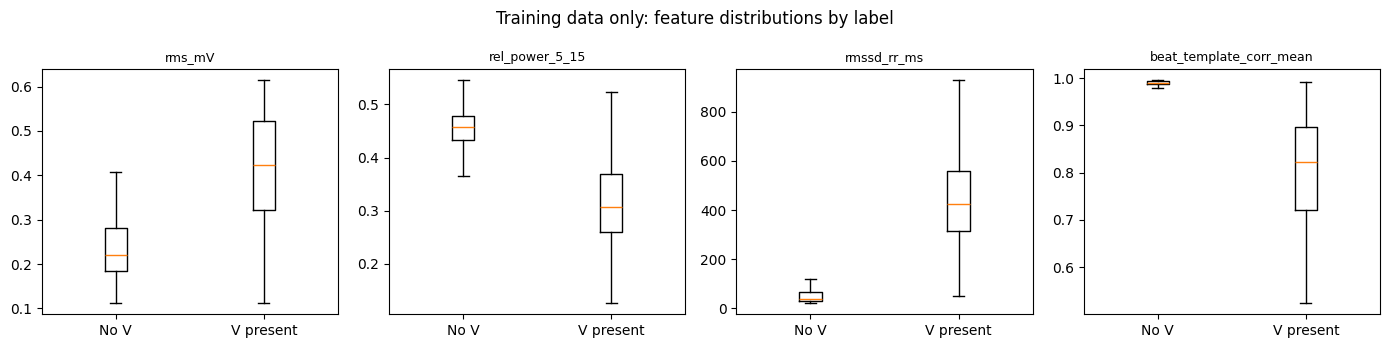

In [18]:
parts = {name: full_table.loc[full_table['split'].eq(name)].copy()
         for name in SPLITS}
train, val = parts['train'], parts['val']
for name, frame in [('train',train), ('val',val)]:
    if frame['target'].nunique() != 2:
        raise ValueError(f'{name}에 두 클래스가 필요합니다. 기록 길이 설정을 확인하세요.')
summary = (pd.concat([train,val]).groupby(['split','record'])['target']
           .agg(windows='size', positives='sum', positive_rate='mean'))
display(summary)
missing = train[FEATURE_COLUMNS].replace([np.inf,-np.inf],np.nan).isna().mean()
display(missing.sort_values(ascending=False).head(10).rename('train_missing_fraction'))
# 입력에는 특징 열만 넣습니다. 무한대는 결측으로 바꿔 Pipeline에서 대체합니다.
X_train = train[FEATURE_COLUMNS].replace([np.inf,-np.inf],np.nan)
y_train = train['target'].astype(int)
X_val = val[FEATURE_COLUMNS].replace([np.inf,-np.inf],np.nan)
y_val = val['target'].astype(int)

# 이 그림은 train의 두 라벨에서 특징이 어떻게 분포하는지 보는 탐색이며 test를 사용하지 않습니다.
plot_features = ['rms_mV','rel_power_5_15','rmssd_rr_ms','beat_template_corr_mean']
fig, axs = plt.subplots(1,4,figsize=(14,3.5))
for ax, name in zip(axs,plot_features):
    values = [train.loc[train.target.eq(k),name].dropna().to_numpy() for k in [0,1]]
    ax.boxplot(values, showfliers=False)
    ax.set_xticks([1,2],CLASS_NAMES)
    ax.set_title(name,fontsize=9)
fig.suptitle('Training data only: feature distributions by label')
plt.tight_layout(); plt.show()


## 6. Pipeline으로 전처리와 ML 학습

| 모델 | 핵심 원리 | 이 코드의 전처리 |
|---|---|---|
| Logistic Regression | 특징의 가중합을 sigmoid로 변환 | 결측 대체 → 열별 표준화 → 분류 |
| Random Forest | 여러 결정나무의 예측을 평균 | 결측 대체 → 300개 나무 |
| HistGradientBoosting | 손실을 줄이는 방향으로 나무를 순서대로 추가 | 결측 대체 → 150회 부스팅 |

로지스틱 회귀는 $p=1/(1+e^{-(b+\sum_j w_jx_j)})$를 계산합니다. 특징마다 단위와 크기가 달라 LR에서는 열별 표준화를 사용합니다. 이 표준화는 **714개 훈련 창에서 각 특징 열의 평균·표준편차를 구하는 것**으로, 원파형 하나를 z-score로 바꾸는 것과 다릅니다.

`Pipeline.fit(X_train,y_train)`은 결측 대체값·표준화 통계·분류기를 train으로만 학습합니다. validation/test에서는 다시 fit하지 않고 그 변환을 그대로 사용합니다.

LR/RF에는 클래스 가중치를, 부스팅에는 기본 손실을 사용합니다. 따라서 이 실습은 실제 설정들의 비교이며 알고리즘의 일반적 우열을 결론 내리는 실험은 아닙니다. 추가 하이퍼파라미터 탐색은 하지 않습니다.

In [24]:
def imputer():
    # 훈련에서 열 전체가 결측이어도 열을 유지합니다.
    return SimpleImputer(strategy='median', keep_empty_features=True)

# 각 Pipeline은 모델별 전처리까지 포함합니다. 아래 .fit은 train 데이터에만 호출합니다.
models = {
    'LogisticRegression': Pipeline([
        # LR의 표준화는 특징 열별 train 통계로 학습합니다. val/test에서 새 통계를 계산하지
        # 않습니다.
        ('impute',imputer()), ('scale',StandardScaler()),
        ('model',LogisticRegression(C=1, class_weight='balanced',
                                    max_iter=2000, random_state=SEED))]),
    'RandomForest': Pipeline([
        ('impute',imputer()),
        ('model',RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
            max_features='sqrt', class_weight='balanced_subsample',
            random_state=SEED,n_jobs=2))]),
    'HistGradientBoosting': Pipeline([
        ('impute',imputer()),
        ('model',HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=7,
            min_samples_leaf=15, learning_rate=.05, l2_regularization=1,
            early_stopping=False, random_state=SEED))])
}

# classes_에서 정답 1의 열을 찾아 점수를 꺼냅니다. 열 번호를 무조건 1로 가정하지 않습니다.
def positive_score(model, X):
    positive_index = list(model.classes_).index(1)
    return model.predict_proba(X)[:,positive_index]

for name, model in models.items():
    # 결측 대체와 필요한 표준화, 분류기까지 한 번에 학습합니다.
    model.fit(X_train,y_train)
    print('학습 완료:',name)


학습 완료: LogisticRegression
학습 완료: RandomForest
학습 완료: HistGradientBoosting


## 7. Validation에서 모델 선택하기

| 지표 | 읽는 방법 |
|---|---|
| AP | 양성을 높은 점수 순서로 잘 모으는가? 양성 비율과 함께 해석합니다. |
| AUROC | 양성 점수가 음성보다 높은 순서로 놓이는가? |
| F1 | 정밀도와 재현율의 균형. 임계값에 따라 달라집니다. |
| BAcc | `(양성 재현율 + 특이도) / 2`. 두 클래스 성능을 함께 봅니다. |

**세 후보 중 validation AP가 가장 높은 모델**을 고릅니다. 동률이면 후보 목록의 순서를 따릅니다. 이 표의 F1 등 판정 지표는 아직 임계값 **0.5** 기준입니다.

AP는 PR 곡선을 요약하지만 사다리꼴 PR-AUC와 계산식이 다릅니다. 아직 test 결과로 모델을 고르지 않습니다.

In [25]:
def score_metrics(y, score, threshold=.5):
    y = np.asarray(y,dtype=int)
    score = np.asarray(score,dtype=float)
    # 연속 점수와 0/1 판정은 다릅니다. 임계값은 F1·재현율·특이도 등에 영향을 줍니다.
    pred = (score >= threshold).astype(int)
    # 두 클래스가 모두 없으면 AP/AUROC/BAcc는 NaN, 분모가 없는 정밀도/재현율/F1은 아래 설정에
    # 따라 0입니다.
    both = len(np.unique(y)) == 2
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'n':len(y), 'positive_rate':float(y.mean()),
        'AP':float(average_precision_score(y,score)) if both else np.nan,
        'AUROC':float(roc_auc_score(y,score)) if both else np.nan,
        'F1':float(f1_score(y,pred,zero_division=0)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'specificity':float(tn/(tn+fp)) if tn+fp else np.nan,
        'balanced_accuracy':float(balanced_accuracy_score(y,pred)) if both else np.nan,
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}

val_scores = {name:positive_score(model,X_val) for name,model in models.items()}
validation_table = pd.DataFrame({
    name:score_metrics(y_val,score) for name,score in val_scores.items()
}).T
validation_table.index.name='model'
display(validation_table.round(4))
# 세 모델 중 validation AP가 가장 높은 모델을 고릅니다.
CANDIDATES = ['LogisticRegression','RandomForest','HistGradientBoosting']
best_name = max(CANDIDATES,key=lambda name:validation_table.loc[name,'AP'])
best_model = models[best_name]
print('검증 AP로 선택한 모델:',best_name)


,n,positive_rate,AP,AUROC,F1,precision,recall,specificity,balanced_accuracy,tn,fp,fn,tp
model,,,,,,,,,,,,,
LogisticRegression,357.0,0.5014,0.8443,0.9267,0.8496,0.7417,0.9944,0.6517,0.8230,116.0,62.0,1.0,178.0
RandomForest,357.0,0.5014,0.9540,0.9550,0.8411,0.9507,0.7542,0.9607,0.8574,171.0,7.0,44.0,135.0
HistGradientBoosting,357.0,0.5014,0.9637,0.9711,0.8571,0.9650,0.7709,0.9719,0.8714,173.0,5.0,41.0,138.0


검증 AP로 선택한 모델: HistGradientBoosting


## 8. Validation에서 판정 임계값 선택하기

모델 선택과 임계값 선택은 별개입니다.

1. 앞에서는 **validation AP**로 모델을 골랐습니다.
2. 여기서는 그 모델의 **validation F1**이 가장 높은 임계값을 고릅니다.
3. 모델과 임계값을 고정해 마지막 test에 적용합니다.

0~1을 0.005 간격으로 비교하고, F1이 같으면 더 높은 임계값을 선택합니다. 0.5가 항상 최선은 아니며, 클래스 가중치를 사용한 점수를 실제 사건 확률로 그대로 해석하지 않습니다. 이번 기준은 교육용 F1 최적화이며 임상 운영 기준을 정하는 과정은 아닙니다.

현재 첨부 실행에서는 HistGradientBoosting과 임계값 0.10이 선택됐습니다. 설정·환경이 바뀌면 달라질 수 있으므로 실제 출력값을 사용하세요.

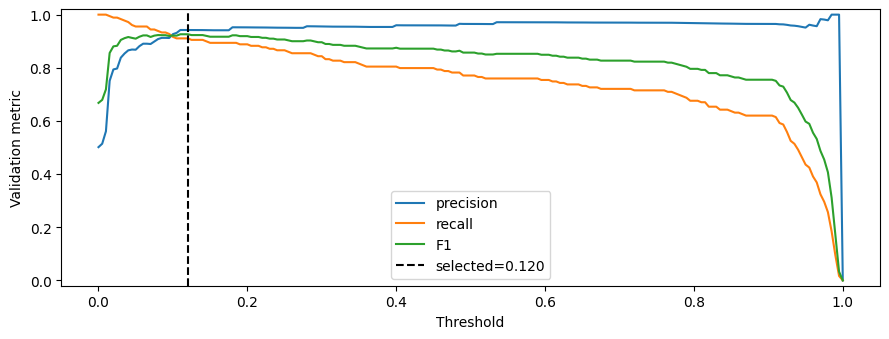

고정할 모델: HistGradientBoosting  / 임계값: 0.12


,n,positive_rate,AP,AUROC,F1,precision,recall,specificity,balanced_accuracy,tn,fp,fn,tp
0,357,0.5014,0.9637,0.9711,0.9261,0.9422,0.9106,0.9438,0.9272,168,10,16,163


In [30]:
thresholds = np.linspace(0,1,201)
threshold_table = pd.DataFrame([
    {'threshold':float(t), **score_metrics(y_val,val_scores[best_name],t)}
    for t in thresholds
])
# F1을 내림차순, 동률이면 threshold도 내림차순으로 정렬해 첫 행을 고릅니다.
best_row = threshold_table.sort_values(['F1','threshold'],ascending=[False,False]).iloc[0]
# 여기서 정한 값을 test에서 바꾸지 않습니다.
THRESHOLD = float(best_row['threshold'])
fig,ax = plt.subplots(figsize=(9,3.5))
for metric in ['precision','recall','F1']:
    ax.plot(threshold_table.threshold,threshold_table[metric],label=metric)
ax.axvline(THRESHOLD,color='black',ls='--',label=f'selected={THRESHOLD:.3f}')
ax.set(xlabel='Threshold',ylabel='Validation metric',ylim=(-.02,1.02))
ax.legend(); plt.tight_layout(); plt.show()
print('고정할 모델:',best_name,' / 임계값:',THRESHOLD)
display(pd.DataFrame([score_metrics(y_val,val_scores[best_name],THRESHOLD)]).round(4))


## 9. 특징 중요도: 무엇을 이용해 예측했을까?

Permutation importance는 **validation의 특징 한 열을 섞었을 때 AP가 얼마나 감소하는지** 봅니다. 모델을 다시 학습하지 않습니다.

첨부 결과에서는 `rmssd_rr_ms`, `rr_cv` 등 박동 간격 변동 특징이 크게 기여했습니다. 모델이 창 안의 박동 간격 정보를 활용했음을 시사하지만, 이것만으로 생리적 인과관계를 증명하지는 않습니다. 자동 검출 오류나 기록별 차이도 영향을 줄 수 있습니다.

상관된 특징은 서로 대체할 수 있습니다. 음의 중요도는 섞은 뒤 점수가 좋아졌다는 뜻이고, 오차 막대는 **셔플 반복의 표준편차**입니다. 이 표를 보고 같은 validation/test에 맞춰 특징을 골라 다시 학습하지는 않습니다.

,feature,AP_drop_mean,shuffle_std
40,rmssd_rr_ms,0.1391,0.0196
39,rr_cv,0.0529,0.0099
19,spectral_peak_hz,0.0219,0.0039
4,peak_to_peak_mV,0.0163,0.0050
41,pnn50_rr_pct,0.0078,0.0054
25,stft_rel_5_15_mean,0.0032,0.0013
20,spectral_centroid_hz,0.0010,0.0004
14,rel_power_0p5_5,0.0006,0.0007
16,rel_power_5_15,0.0004,0.0004
32,wavelet_db4_D3_rel_energy,0.0003,0.0003


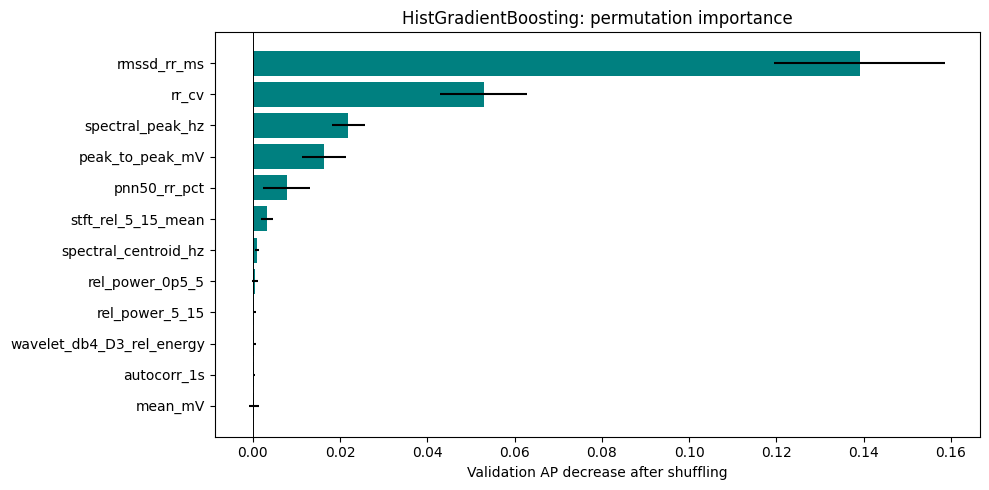

In [32]:
# 선택한 모델은 고정하고 validation의 특징 한 열만 섞어 AP 감소량을 반복 측정합니다.
importance = permutation_importance(best_model,X_val,y_val,
    scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=1)
importance_table = pd.DataFrame({'feature':FEATURE_COLUMNS,
    'AP_drop_mean':importance.importances_mean,
    'shuffle_std':importance.importances_std}).sort_values('AP_drop_mean',ascending=False)
display(importance_table.head(12).round(4))
# 상위 12개를 막대 그림에 표시합니다. 중요도가 낮다고 여기서 열을 제거해 재학습하지 않습니다.
shown = importance_table.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(shown.feature,shown.AP_drop_mean,xerr=shown.shuffle_std,color='teal')
ax.axvline(0,color='black',lw=.7)
ax.set(xlabel='Validation AP decrease after shuffling',title=f'{best_name}: permutation importance')
plt.tight_layout(); plt.show()


## 10. Test: 고정한 모델과 임계값 평가

이제 test의 357개 창을 평가합니다. 모델과 임계값을 바꾸거나 train+validation으로 다시 fit하지 않습니다.

| 항목 | 의미 |
|---|---|
| TP / FN | V 포함 창을 맞힘 / 놓침 |
| TN / FP | V 없는 창을 맞힘 / 포함이라고 오탐 |

혼동행렬은 실제 라벨이 행, 예측 라벨이 열입니다. ROC/PR 곡선은 연속 점수로 계산하고, 혼동행렬·F1·BAcc는 고정 임계값으로 계산합니다.

평가 단위는 **30초 창**입니다. 박동별 검출 성능이나 시간당 독립 경보 수와 구분합니다.

,n,positive_rate,AP,AUROC,F1,precision,recall,specificity,balanced_accuracy,tn,fp,fn,tp
HistGradientBoosting,357,0.6639,0.9998,0.9996,0.9916,0.9916,0.9916,0.9833,0.9874,118,2,2,235


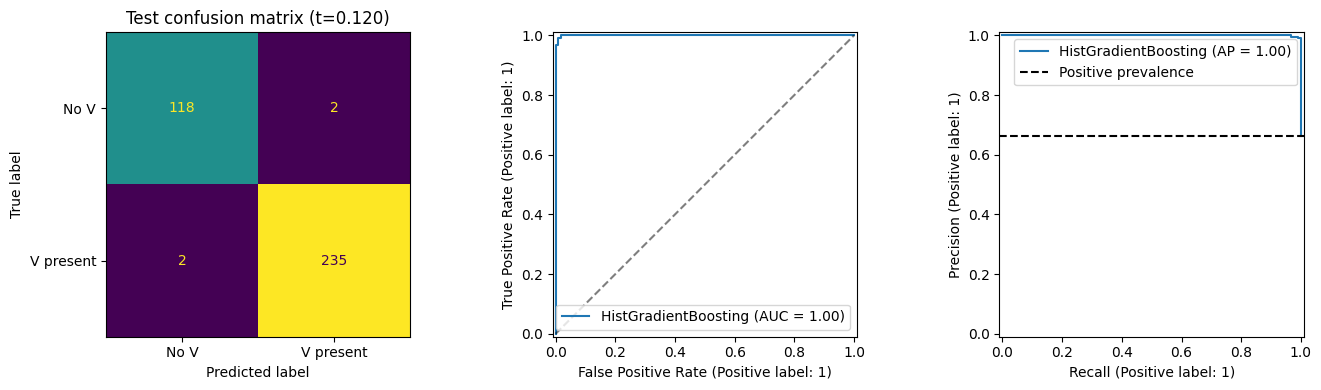

In [33]:
# 모델과 임계값을 모두 정한 후 test를 평가합니다. .fit을 다시 호출하지 않습니다.
test = parts['test']
X_test = test[FEATURE_COLUMNS].replace([np.inf,-np.inf],np.nan)
y_test = test.target.astype(int)
# 점수 순위 지표에는 score를, 혼동행렬에는 고정 임계값으로 얻은 pred를 사용합니다.
test_score = positive_score(best_model,X_test)
test_pred = (test_score >= THRESHOLD).astype(int)
final_metrics = score_metrics(y_test,test_score,THRESHOLD)
display(pd.DataFrame([final_metrics],index=[best_name]).round(4))

fig,axs=plt.subplots(1,3,figsize=(14,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,labels=[0,1],
    display_labels=CLASS_NAMES,ax=axs[0],colorbar=False)
axs[0].set_title(f'Test confusion matrix (t={THRESHOLD:.3f})')
if y_test.nunique()==2:
    RocCurveDisplay.from_predictions(y_test,test_score,ax=axs[1],name=best_name)
    axs[1].plot([0,1],[0,1],'k--',alpha=.5)
    PrecisionRecallDisplay.from_predictions(y_test,test_score,ax=axs[2],name=best_name)
    axs[2].axhline(y_test.mean(),color='black',ls='--',label='Positive prevalence')
    axs[2].legend()
else:
    for ax in axs[1:]:ax.text(.1,.5,'Both classes required')
plt.tight_layout(); plt.show()


### 현재 데이터셋의 결과 읽기

이번 test는 **117·203·208의 3개 기록, 357개 창**이며 **음성 120개·양성 237개**입니다.

첨부 실행의 HistGradientBoosting은 `TN=118, FP=2, FN=2, TP=235`로, F1 약 0.992와 BAcc 약 0.987을 얻었습니다. 음성 창 120개 중 118개를 음성으로, 양성 창 237개 중 235개를 양성으로 분류한 결과입니다.

다음 절에서 **기록별로 양성·음성이 어떻게 분포하고 어디서 오류가 나는지** 확인합니다. 수치는 첨부 실행의 예이며 재실행 결과표가 기준입니다.


## 11. 기록별 성능과 시간에 따른 점수

현재 test는 기록마다 클래스 구성이 크게 다릅니다.

| 기록 | 음성 창 | 양성 창 | 해석할 점 |
|---|---:|---:|---|
| 117 | 119 | 0 | V 없는 구간에서 오탐을 확인 |
| 203 | 0 | 119 | V 포함 구간에서 놓침을 확인 |
| 208 | 1 | 118 | 음성이 1개라 특이도가 매우 불안정 |

한 클래스만 있는 기록의 AP/AUROC/BAcc는 이 코드에서 `NaN`으로 표시합니다. 현재 결과는 전체 BAcc가 높아도 208의 유일한 음성을 양성으로 오탐해 그 기록의 특이도가 0일 수 있음을 보여 줍니다.

`record_macro_mean`은 기록별 지표의 단순 평균이며 NaN은 제외합니다. 다만 F1·precision·recall은 코드상 분모가 없으면 0을 넣으므로, 모든 지표에서 정의 불가능한 기록이 자동 제외되는 것은 아닙니다. 전체 창을 합친 점수와 구분해 읽으세요.

,record,n,positive_rate,AP,AUROC,F1,precision,recall,specificity,balanced_accuracy,tn,fp,fn,tp
0,117,119,0.0000,NaN,NaN,0.0000,0.0000,0.0000,0.9916,NaN,118,1,0,0
1,203,119,1.0000,NaN,NaN,1.0000,1.0000,1.0000,NaN,NaN,0,0,0,119
2,208,119,0.9916,0.9994,0.9322,0.9872,0.9915,0.9831,0.0000,0.4915,0,1,2,116


,record_macro_mean
AP,0.999413
AUROC,0.932203
F1,0.662411
recall,0.661017
specificity,0.495798


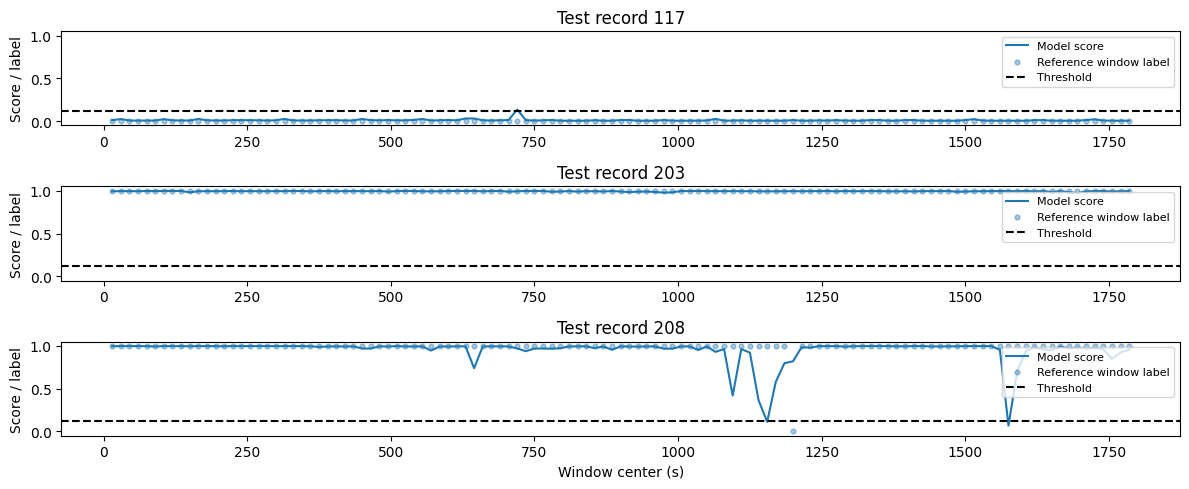

In [35]:
predictions = test[META_COLUMNS].copy()
predictions['score']=test_score
predictions['prediction']=test_pred
predictions['correct']=predictions.target.eq(predictions.prediction)
record_metrics=[]
# 기록마다 라벨 분포가 다르므로 전체 지표와 기록별 지표를 함께 봅니다.
for record_id,group in predictions.groupby('record',sort=False):
    record_metrics.append({'record':record_id,
        **score_metrics(group.target,group.score,THRESHOLD)})
record_metrics=pd.DataFrame(record_metrics)
display(record_metrics.round(4))
# 열별 평균에서 NaN은 제외하지만, zero_division=0으로 채운 값은 0으로 평균에 포함됩니다.
display(record_metrics[['AP','AUROC','F1','recall','specificity']].mean()
        .rename('record_macro_mean').to_frame())

fig,axs=plt.subplots(len(record_metrics),1,figsize=(12,5),squeeze=False)
for ax,(record_id,group) in zip(axs[:,0],predictions.groupby('record',sort=False)):
    centers=(group.window_start_s+group.window_end_s)/2
    ax.plot(centers,group.score,label='Model score')
    ax.scatter(centers,group.target,s=12,alpha=.4,label='Reference window label')
    ax.axhline(THRESHOLD,color='black',ls='--',label='Threshold')
    ax.set(title=f'Test record {record_id}',ylabel='Score / label',ylim=(-.05,1.05))
    ax.legend(loc='upper right',fontsize=8)
axs[-1,0].set_xlabel('Window center (s)')
plt.tight_layout(); plt.show()


## 12. 오분류 창을 파형으로 확인하기

FP가 있으면 가장 높은 점수의 FP를, FN이 있으면 가장 낮은 점수의 FN을 확인합니다. 오류가 전혀 없으면 정분류 예시를 표시합니다.

**정답과 판정은 30초 창 하나에 하나씩** 붙지만, 그림은 가독성을 위해 V 근처 또는 중앙의 **6초만 확대**합니다. 빨간 점선이 세 개 보여도 그것은 V 박동 세 개이며 오분류 창 세 개를 뜻하지 않습니다.

전문가 주석은 이 오류 그림과 라벨 생성에만 사용했습니다. 오류에서 새로운 가설을 얻을 수는 있지만, 같은 test를 보고 모델을 수정했다면 새 자료로 다시 평가해야 합니다.

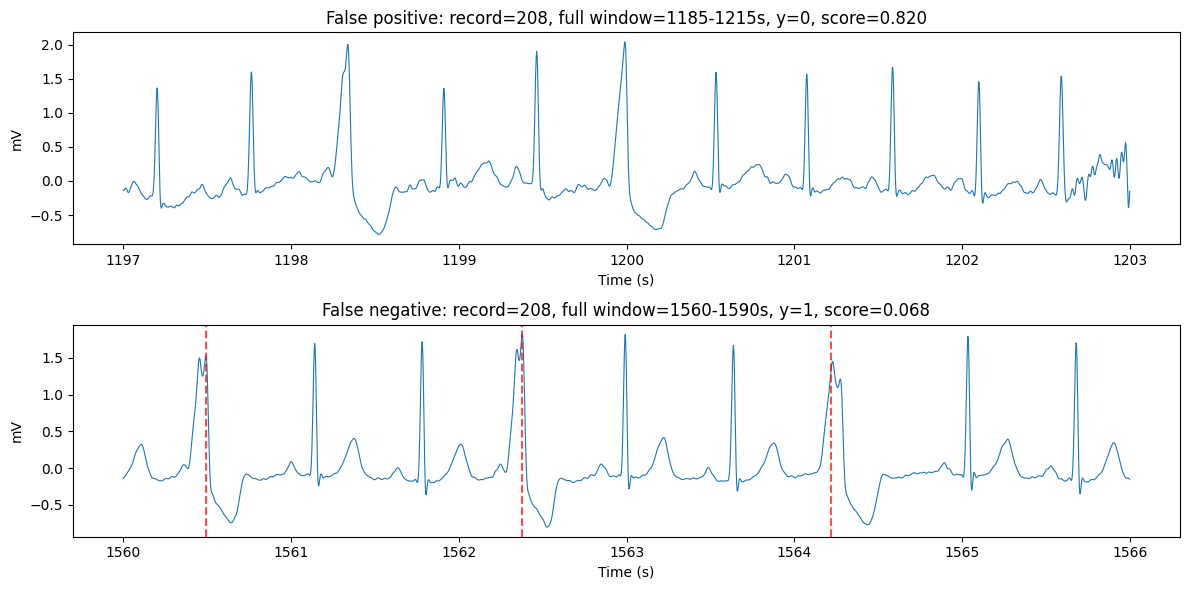

In [36]:
examples=[]
for title,condition,ascending in [
    ('False positive',(predictions.target==0)&(predictions.prediction==1),False),
    ('False negative',(predictions.target==1)&(predictions.prediction==0),True)]:
    candidates=predictions.loc[condition].sort_values('score',ascending=ascending)
    if len(candidates):examples.append((title,candidates.iloc[0]))
if not examples:
    examples=[('Correct prediction',predictions.iloc[0])]
fig,axs=plt.subplots(len(examples),1,figsize=(12,3*len(examples)),squeeze=False)
for ax,(title,row) in zip(axs[:,0],examples):
    cached=record_cache[str(row.record)]
    ann=cached['ann']
    samples=np.asarray(ann.sample)
    symbols=np.asarray(ann.symbol)
    start,end=int(round(row.window_start_s*FS)),int(round(row.window_end_s*FS))
    ventricular=samples[(samples>=start)&(samples<end)&(symbols=='V')]
    # 이 그림의 6초 확대 중심입니다. 모델은 이 6초가 아니라 30초 전체 특징으로 판정했습니다.
    center=int(ventricular[0]) if len(ventricular) else (start+end)//2
    view_start=max(start,min(center-3*FS,end-6*FS))
    view_end=min(end,view_start+6*FS)
    tt=np.arange(view_start,view_end)/FS
    ax.plot(tt,cached['ecg'][view_start:view_end],lw=.8)
    # 표시된 V 선 개수는 박동 수입니다. 평가의 TP/FP/FN/TN은 창 수입니다.
    for p in ventricular[(ventricular>=view_start)&(ventricular<view_end)]:
        ax.axvline(p/FS,color='red',alpha=.7,ls='--')
    ax.set(title=f'{title}: record={row.record}, full window={row.window_start_s:g}-{row.window_end_s:g}s, '
                 f'y={row.target}, score={row.score:.3f}',xlabel='Time (s)',ylabel='mV')
plt.tight_layout(); plt.show()


## 정리

- 원시 ECG를 46개 특징으로 요약해 일반적인 ML 모델에 입력했습니다.
- X는 자동 계산 특징, y는 전문가 V 주석으로 분리했습니다.
- 전처리는 train으로 학습하고, 모델·임계값은 validation으로 골랐습니다.
- Test의 전체 지표와 기록별 오류, 원파형을 함께 해석했습니다.

이 실습은 12개 기록의 작은 교육용 비교입니다. 겹치는 창의 수가 많아도 독립적인 환자 수가 늘어나는 것은 아닙니다.

## 참고 자료

- [MIT-BIH 데이터](https://physionet.org/content/mitdb/1.0.0/)
- [MIT-BIH 주석 설명](https://physionet.org/physiobank/database/html/mitdbdir/intro.htm)
- [WFDB XQRS](https://wfdb.readthedocs.io/en/latest/processing.html)
- [scikit-learn Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)